# Supermarket Sales Analysis


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\RitikaB\PycharmProjects\Supermarket_Sales_Analysis\dataset
['SuperMarket Analysis.csv', 'SuperMarket Analysis.ipynb']


In [4]:
data = pd.read_csv("SuperMarket Analysis.csv")

In [5]:
data

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,Giza,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1/29/2019,1:46:00 PM,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3/2/2019,5:16:00 PM,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,Alex,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2/9/2019,1:22:00 PM,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,Alex,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2/22/2019,3:33:00 PM,Cash,65.82,4.761905,3.2910,4.1


In [6]:
data["Date"] = pd.to_datetime(data["Date"])

print(data["Date"].dtype)
print(data["Date"].head())

datetime64[us]
0   2019-01-05
1   2019-03-08
2   2019-03-03
3   2019-01-27
4   2019-02-08
Name: Date, dtype: datetime64[us]


# Supermarket Sales Analysis

Basic Sales Analysis


In [7]:
# 1. Calculate Total Sales
total_sales = data["Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 322966.749


In [8]:
# 2. Calculate Total Quantity Sold
total_quantity = data["Quantity"].sum()

print("Total Quantity Sold:", total_quantity)


Total Quantity Sold: 5510


In [9]:
# 3. Calculate Average Customer Rating
average_rating = data["Rating"].mean()

print("Average Customer Rating:", average_rating)

Average Customer Rating: 6.9727


Product Line Analysis

In [10]:
# Product Line Wise Total Sales

product_sales = data.groupby("Product line")["Sales"].sum()

print(product_sales)

Product line
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Food and beverages        56144.8440
Health and beauty         49193.7390
Home and lifestyle        53861.9130
Sports and travel         55122.8265
Name: Sales, dtype: float64


In [12]:
# Find the product category with the highest total sales
highest_sales = product_sales.idxmax()

print("Highest Sales Product Category:", highest_sales)
print("Sales Amount:", product_sales.max())

Highest Sales Product Category: Food and beverages
Sales Amount: 56144.844


In [13]:
# Find the product category with the lowest total sales
lowest_sales = product_sales.idxmin()

print("Lowest Sales Product Category:", lowest_sales)
print("Sales Amount:", product_sales.min())

Lowest Sales Product Category: Health and beauty
Sales Amount: 49193.739


In [14]:
# Product Line Wise Gross Income

product_income = data.groupby("Product line")["gross income"].sum()

print(product_income)

Product line
Electronic accessories    2587.5015
Fashion accessories       2585.9950
Food and beverages        2673.5640
Health and beauty         2342.5590
Home and lifestyle        2564.8530
Sports and travel         2624.8965
Name: gross income, dtype: float64


In [15]:
#highest gross income
highest_income = product_income.idxmax()

print("Highest Gross Income Category:", highest_income)
print("Gross Income:", product_income.max())

Highest Gross Income Category: Food and beverages
Gross Income: 2673.564


In [16]:
print("========== PRODUCT ANALYSIS ==========")

print("Highest Sales Category:", product_sales.idxmax())
print("Lowest Sales Category:", product_sales.idxmin())
print("Highest Gross Income Category:", product_income.idxmax())

========== PRODUCT ANALYSIS ==========
Highest Sales Category: Food and beverages
Lowest Sales Category: Health and beauty
Highest Gross Income Category: Food and beverages


In [17]:
# Calculate average sales for each product category
average_product_sales = data.groupby("Product line")["Sales"].mean()

print(average_product_sales)

highest_average_sales = average_product_sales.idxmax()

print("Highest Average Sales Category:", highest_average_sales)
print("Average Sales Amount:", average_product_sales.max())

Product line
Electronic accessories    319.632538
Fashion accessories       305.089298
Food and beverages        322.671517
Health and beauty         323.643020
Home and lifestyle        336.636956
Sports and travel         332.065220
Name: Sales, dtype: float64
Highest Average Sales Category: Home and lifestyle
Average Sales Amount: 336.63695625


City & Branch Analysis


In [18]:
#city with highest  number of sales
city_sales = data.groupby("City")["Sales"].sum()

print(city_sales)

highest_city_sales = city_sales.idxmax()

print("Highest Sales City:", highest_city_sales)
print("Total Sales:", city_sales.max())

City
Mandalay     106197.6720
Naypyitaw    110568.7065
Yangon       106200.3705
Name: Sales, dtype: float64
Highest Sales City: Naypyitaw
Total Sales: 110568.7065


In [19]:
#To find which branch has highest  no of sales
branch_sales = data.groupby("Branch")["Sales"].sum()

print(branch_sales)

highest_branch = branch_sales.idxmax()

print("Highest Sales Branch:", highest_branch)
print("Total Sales:", branch_sales.max())

Branch
Alex     106200.3705
Cairo    106197.6720
Giza     110568.7065
Name: Sales, dtype: float64
Highest Sales Branch: Giza
Total Sales: 110568.7065


In [20]:
#Average sales of each city
average_city_sales = data.groupby("City")["Sales"].mean()

print(average_city_sales)

City
Mandalay     319.872506
Naypyitaw    337.099715
Yangon       312.354031
Name: Sales, dtype: float64


Customer Analysis

In [21]:
# 1. Male vs Female customers - Who spends the most
gender_sales = data.groupby("Gender")["Sales"].sum()

print(gender_sales)

highest_gender_sales = gender_sales.idxmax()

print("Highest Spending Gender:", highest_gender_sales)
print("Total Sales:", gender_sales.max())

Gender
Female    194671.8375
Male      128294.9115
Name: Sales, dtype: float64
Highest Spending Gender: Female
Total Sales: 194671.8375


In [22]:
#2.Member vs Normal customers - who is the highest spending customer
customer_sales = data.groupby("Customer type")["Sales"].sum()

print(customer_sales)

highest_customer_type = customer_sales.idxmax()

print("Highest Spending Customer Type:", highest_customer_type)
print("Total Sales:", customer_sales.max())


Customer type
Member    189694.764
Normal    133271.985
Name: Sales, dtype: float64
Highest Spending Customer Type: Member
Total Sales: 189694.764


In [23]:
#3.Male vs Female – average purchase amount
average_gender_sales = data.groupby("Gender")["Sales"].mean()

print(average_gender_sales)

Gender
Female    340.931414
Male      299.055738
Name: Sales, dtype: float64


In [24]:
# Customer type wise average spending
average_customer_sales = data.groupby("Customer type")["Sales"].mean()

print(average_customer_sales)


Customer type
Member    335.742945
Normal    306.372379
Name: Sales, dtype: float64


In [25]:
# Gender-wise customer count
gender_count = data["Gender"].value_counts()

print(gender_count)

Gender
Female    571
Male      429
Name: count, dtype: int64


Payment Method Analysis

In [26]:
# Most popular payment method
payment_count = data["Payment"].value_counts()

print(payment_count)

popular_payment = payment_count.idxmax()

print("Most Popular Payment Method:", popular_payment)
print("Number of Transactions:", payment_count.max())

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64
Most Popular Payment Method: Ewallet
Number of Transactions: 345


In [27]:
# Highest Sales Payment Method
payment_sales = data.groupby("Payment")["Sales"].sum()

print(payment_sales)

highest_payment_sales = payment_sales.idxmax()

print("Highest Sales Payment Method:", highest_payment_sales)
print("Total Sales:", payment_sales.max())

Payment
Cash           112206.570
Credit card    100767.072
Ewallet        109993.107
Name: Sales, dtype: float64
Highest Sales Payment Method: Cash
Total Sales: 112206.57


In [28]:
# Average Transaction Value from each payment method
average_payment_sales = data.groupby("Payment")["Sales"].mean()

print(average_payment_sales)

Payment
Cash           326.181890
Credit card    324.009878
Ewallet        318.820600
Name: Sales, dtype: float64


In [ ]:
# Lowest Sales Payment Method
lowest_payment_sales = payment_sales.idxmin()

print("Lowest Sales Payment Method:", lowest_payment_sales)
print("Total Sales:", payment_sales.min())

Daily & Monthly Sales Analysis

----Daily Sales Analysis----

In [29]:
#Daily Sales - date wise
daily_sales = data.groupby("Date")["Sales"].sum()

print(daily_sales)

Date
2019-01-01    4745.1810
2019-01-02    1945.5030
2019-01-03    2078.1285
2019-01-04    1623.6885
2019-01-05    3536.6835
                ...    
2019-03-26    1962.5130
2019-03-27    2902.8195
2019-03-28    2229.4020
2019-03-29    4023.2430
2019-03-30    4487.0595
Name: Sales, Length: 89, dtype: float64


In [30]:
#Highest sale on which date
highest_sales_date = daily_sales.idxmax()

print("Highest Sales Date:", highest_sales_date)
print("Total Sales:", daily_sales.max())

Highest Sales Date: 2019-03-09 00:00:00
Total Sales: 7474.0470000000005


In [ ]:
#Lowest sale on which data
lowest_sales_date = daily_sales.idxmin()

print("Lowest Sales Date:", lowest_sales_date)
print("Total Sales:", daily_sales.min())

----Monthly Sales Analysis----

In [31]:
data["Month"] = data["Date"].dt.to_period("M")

monthly_sales = data.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
2019-01    116291.868
2019-02     97219.374
2019-03    109455.507
Freq: M, Name: Sales, dtype: float64


In [33]:
#Highest and Lowest Sales Month
highest_sales_month = monthly_sales.idxmax()

print("Highest Sales Month:", highest_sales_month)
print("Total Sales:", monthly_sales.max())
lowest_sales_month = monthly_sales.idxmin()

print("Lowest Sales Month:", lowest_sales_month)
print("Total Sales:", monthly_sales.min())

Highest Sales Month: 2019-01
Total Sales: 116291.868
Lowest Sales Month: 2019-02
Total Sales: 97219.374


$$---Daily Sales Trend---$$


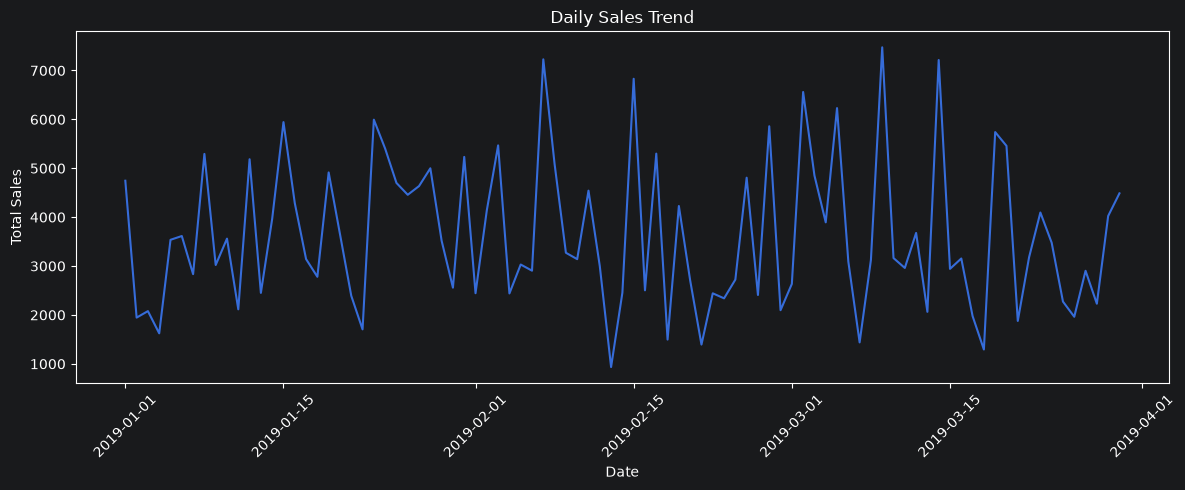

In [34]:
plt.figure(figsize=(12, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

$$---Monthly Sales---$$


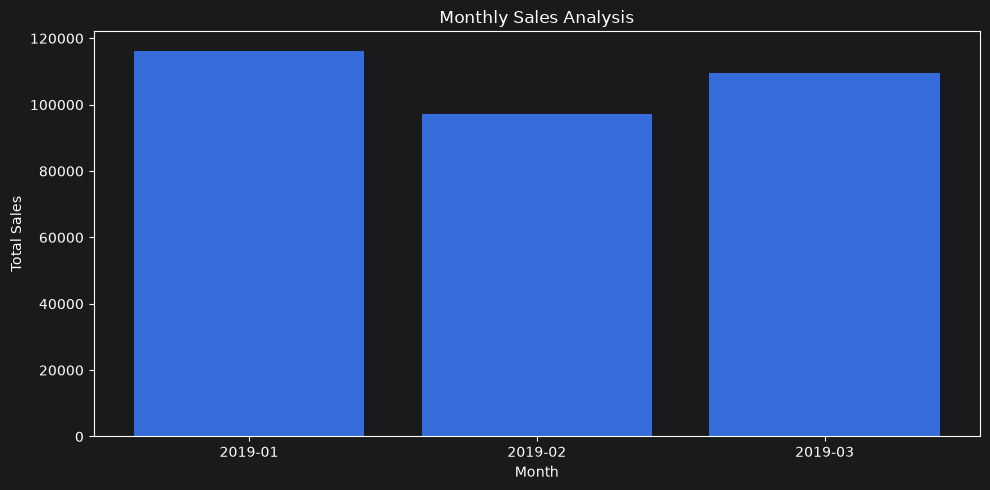

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(monthly_sales.index.astype(str), monthly_sales.values)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

$$--Product Line Sales--$$


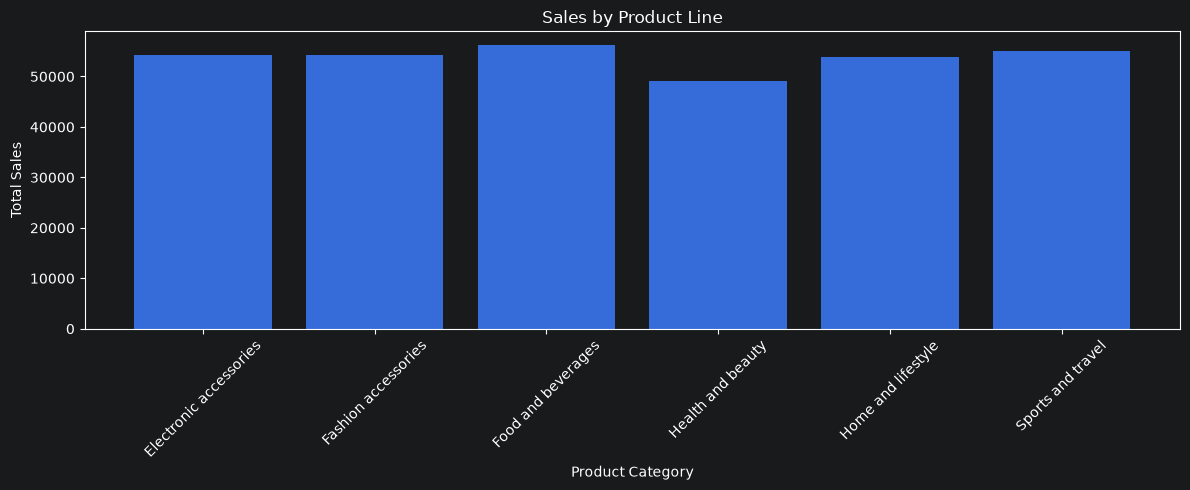

In [36]:
plt.figure(figsize=(12, 5))

plt.bar(product_sales.index, product_sales.values)

plt.title("Sales by Product Line")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()